**ESOPHAGEAL CANCER CLASSIFICATION USING VGG16 FOR SAVE IMAGES**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
pip install tensorflow


**READ THE FILE PATH AND LOAD THE MODEL FOR TRAINING**

In [ ]:
# Define paths to your datasets
train_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/train'
val_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/val'
test_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/test'

In [ ]:
import tensorflow as tf

# Define image size and batch size
img_size = (640,640)
batch_size = 32

# Load and preprocess the datasets
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'  # Use 'categorical' for multi-class classification
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
)

# Normalize the pixel values to be between 0 and 1
normalization_layer = tf.keras.layers.Rescaling(1./255)

def preprocess(ds):
    ds = ds.map(lambda x, y: (normalization_layer(x), y))
    return ds

train_ds = preprocess(train_ds)
val_ds = preprocess(val_ds)
test_ds = preprocess(test_ds)


Found 751 files belonging to 3 classes.
Found 214 files belonging to 3 classes.
Found 109 files belonging to 3 classes.


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Load the VGG16 model pre-trained on ImageNet, without the top classification layers
base_model = tf.keras.applications.VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(640, 640, 3)
)

# Freeze the base model
base_model.trainable = False

# Get the class names from the training dataset
# Use the original training dataset before preprocessing for class names
class_names = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
).class_names

# Build the model
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')  # Use the class_names variable directly
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Found 751 files belonging to 3 classes.


**TRAIN THE MODEL**

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100  # Adjust as needed
)


Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 317s 10s/step - accuracy: 0.3729 - loss: 1.2098 - val_accuracy: 0.5841 - val_loss: 0.9056
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.5690 - loss: 0.9253 - val_accuracy: 0.7103 - val_loss: 0.8050
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.6521 - loss: 0.8310 - val_accuracy: 0.7196 - val_loss: 0.7174
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.6906 - loss: 0.7618 - val_accuracy: 0.7477 - val_loss: 0.6841
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.7360 - loss: 0.6956 - val_accuracy: 0.7757 - val_loss: 0.6150
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.7291 - loss: 0.6596 - val_accuracy: 0.7804 - val_loss: 0.5820
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.7623 - loss: 0.6290 - val_accuracy: 0.7897 - val_loss: 0.5608
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.7690 - loss: 0.5893 - val_accuracy: 0.7757 -

**TEST DATA EVALUATION**

In [ ]:
loss, accuracy = model.evaluate(test_ds)
print('Test accuracy:', accuracy)


4/4 ━━━━━━━━━━━━━━━━━━━━ 62s 17s/step - accuracy: 0.8355 - loss: 0.3615
Test accuracy: 0.8256880640983582


**CLASSIFICATION REPORT RESULTS AND CONFUSION MATRIX**

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:
  predictions = model.predict(images)
  y_pred.extend(np.argmax(predictions, axis=1))
  y_true.extend(np.argmax(labels, axis=1))

# Access class names from the global variable instead of test_ds
print(classification_report(y_true, y_pred, target_names=class_names))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 559ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
              precision    recall  f1-score   support

   Dysplasia       0.77      0.88      0.82        41
      Normal       0.96      0.76      0.85        34
         SCC       0.80      0.82      0.81        34

    accuracy                           0.83       109
   macro avg       0.84      0.82      0.83       109
weighted avg       0.84      0.83      0.83       109



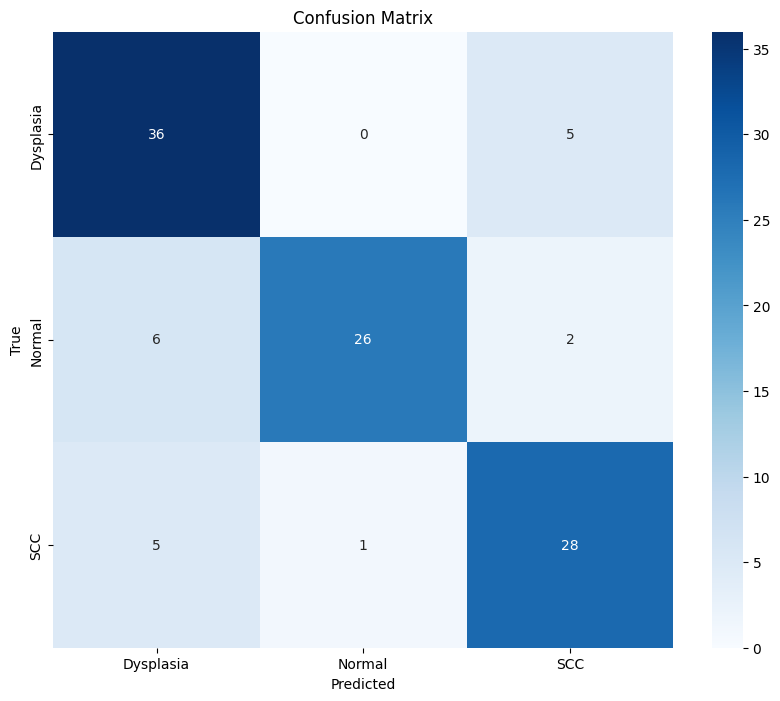

In [ ]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming you have already computed y_true and y_pred as in the previous code

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


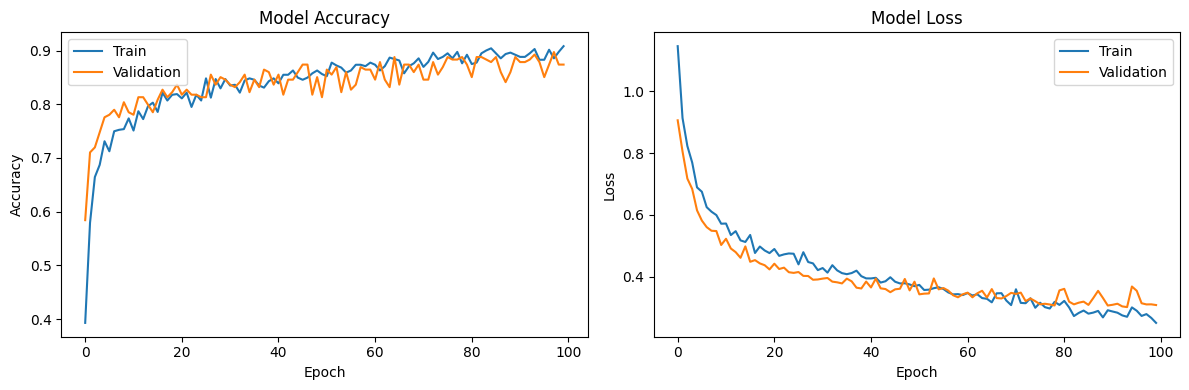

In [ ]:
import matplotlib.pyplot as plt
# Plot training accuracy and loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc='upper right')

plt.tight_layout()
plt.show()


In [ ]:
model.save('/content/drive/MyDrive/my_model_with_historyvgg16.h5')


In [ ]:
model.save('/content/drive/MyDrive/my_model_vgg16.keras')


In [ ]:
import pickle

# Save the model history to a pickle file
with open('/content/drive/MyDrive/trainHistoryDictvgg16', 'wb') as file_pi:
  pickle.dump(history.history, file_pi)


In [ ]:
!mv /content/drive/MyDrive/my_model_with_historyvgg16.h5 /content/drive/MyDrive/Danat/EC
!mv /content/drive/MyDrive/my_model_vgg16.keras /content/drive/MyDrive/Danat/EC
!mv /content/drive/MyDrive/trainHistoryDictvgg16 /content/drive/MyDrive/Danat/EC


**PREDICTION RESULT**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# Select 20 images from the test dataset
sample_images = []
sample_labels = []
count = 0

for images, labels in test_ds.take(100):
  for i in range(images.shape[0]):
    sample_images.append(images[i])
    sample_labels.append(labels[i])
    count += 1
    if count == 20:
      break
  if count == 20:
    break

# Make predictions
predictions = model.predict(np.array(sample_images))

# Display results
plt.figure(figsize=(20, 15))  # Adjust figure size for 20 images
for i in range(20):
  plt.subplot(4, 5, i + 1)  # Adjust subplot layout for 20 images
  # Ensure images are displayed correctly by rescaling to 0-255 and converting to uint8
  plt.imshow((sample_images[i].numpy() * 255).astype("uint8"))
  true_label = class_names[np.argmax(sample_labels[i])]
  predicted_label = class_names[np.argmax(predictions[i])]
  confidence = np.max(predictions[i])
  plt.title(f"True: {true_label}\nPredicted: {predicted_label}\nConfidence: {confidence:.2f}")
  plt.axis('off')
plt.tight_layout()
plt.show()


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import json

# Assuming `history` is the History object returned by model.fit()
with open('training_history.json', 'w') as f:
    json.dump(history.history, f)


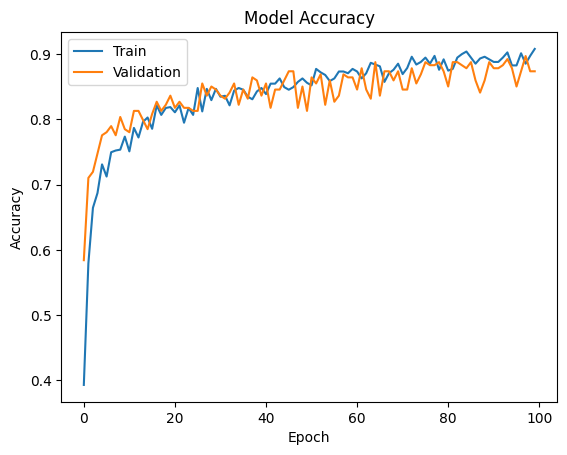

In [ ]:
import json

# Load the training history
with open('training_history.json', 'r') as f:
    history = json.load(f)

# Example: Plot training & validation accuracy values
import matplotlib.pyplot as plt

plt.plot(history['accuracy'])
plt.plot(history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()


In [ ]:
import shutil

# Define the source path (where the file is currently saved)
source_path = 'training_history.json'

# Define the destination path (your working directory or any desired directory)
destination_path = '/content/drive/MyDrive/Danat/EC'

# Move the file
shutil.move(source_path, destination_path)

print(f'File moved to {destination_path}')


File moved to /content/drive/MyDrive/Danat/EC
